# Requirements

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

# Data

In [2]:
ROOT = Path.cwd().parent
train = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols = [f"PAY_{i}" for i in range(6, 0, -1)]  # chronological Apr..Sep

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
      [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


# Markov chain: three state splits

Two-class Markov chain classifier (same structure as the generic model). Each class (non-defaulter / defaulter) has its own initial distribution and transition matrix, fitted on the **train** split only. A sequence is scored by the log-likelihood ratio of the default chain against the non-default chain plus the log prior odds, then Platt-scaled on the validation split.

State splits (raw PAY value -> state):

| Model | States |
|---|---|
| `mk4_1with0` | {-2}, {-1}, {0, 1}, {>=2} |
| `mk4_late1plus` | {-2}, {-1}, {0}, {>=1} |
| `mk5_12merged` | {-2}, {-1}, {0}, {1, 2}, {>=3} |

Assumption: in the request, commas separate states and "and"/"or" inside a state merges those raw values; "more than n" is read as >= n.

In [3]:
# ---- state mappings ----
def make_to_state(groups):
    # groups: list of (lo, hi) inclusive raw-value ranges, one per state, in order; None = open end
    def f(p):
        p = np.asarray(p); s = np.full(p.shape, -1, dtype=int)
        for k, (lo, hi) in enumerate(groups):
            m = (p >= lo) if hi is None else ((p >= lo) & (p <= hi))
            s[m & (s == -1)] = k
        assert (s >= 0).all(), "unmapped PAY value"
        return s
    return f

to_state_4_1with0   = make_to_state([(-2, -2), (-1, -1), (0, 1), (2, None)])
to_state_4_late1plus = make_to_state([(-2, -2), (-1, -1), (0, 0), (1, None)])
to_state_5_12merged = make_to_state([(-2, -2), (-1, -1), (0, 0), (1, 2), (3, None)])

state_labels = {
    "mk4_1with0":    ["-2 no bill", "-1 paid", "0/1 revolving or 1 late", "2+ late"],
    "mk4_late1plus": ["-2 no bill", "-1 paid", "0 revolving", "1+ late"],
    "mk5_12merged":  ["-2 no bill", "-1 paid", "0 revolving", "1-2 late", "3+ late"],
}

In [4]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)   # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             C0=raw_counts(S_tr[y_tr == 0], K), C1=raw_counts(S_tr[y_tr == 1], K),
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_tr"] = m["platt"].predict_proba(m["sc_tr"].reshape(-1, 1))[:, 1]
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build all three ----
markov_models = {
    "mk4_1with0":    build_markov("mk4_1with0",    to_state_4_1with0,    4),
    "mk4_late1plus": build_markov("mk4_late1plus", to_state_4_late1plus, 4),
    "mk5_12merged":  build_markov("mk5_12merged",  to_state_5_12merged,  5),
}

p_mk4_1with0_va,    p_mk4_1with0_te    = markov_models["mk4_1with0"]["p_va"],    markov_models["mk4_1with0"]["p_te"]
p_mk4_late1plus_va, p_mk4_late1plus_te = markov_models["mk4_late1plus"]["p_va"], markov_models["mk4_late1plus"]["p_te"]
p_mk5_12merged_va,  p_mk5_12merged_te  = markov_models["mk5_12merged"]["p_va"],  markov_models["mk5_12merged"]["p_te"]

# Performance comparison

In [5]:
rows = []
for k, m in markov_models.items():
    rows.append(dict(model=k, K=m["K"],
        train_AUC=roc_auc_score(y_tr, m["p_tr"]), val_AUC=roc_auc_score(y_va, m["p_va"]),
        test_AUC=roc_auc_score(y_te, m["p_te"]),
        val_logloss=log_loss(y_va, m["p_va"]), test_logloss=log_loss(y_te, m["p_te"]),
        test_brier=brier_score_loss(y_te, m["p_te"])))
results = pd.DataFrame(rows).set_index("model").round(4)
results

,K,train_AUC,val_AUC,test_AUC,val_logloss,test_logloss,test_brier
model,,,,,,,
mk4_1with0,4,0.7392,0.7411,0.7451,0.4456,0.4489,0.1410
mk4_late1plus,4,0.7317,0.7382,0.7432,0.4479,0.4492,0.1415
mk5_12merged,5,0.7326,0.7384,0.7426,0.4476,0.4488,0.1413


# Data support per transition
Raw (unsmoothed) train counts. Cells with fewer than `MIN_N` observations in either class are unreliable and are greyed out in the log-ratio panel.

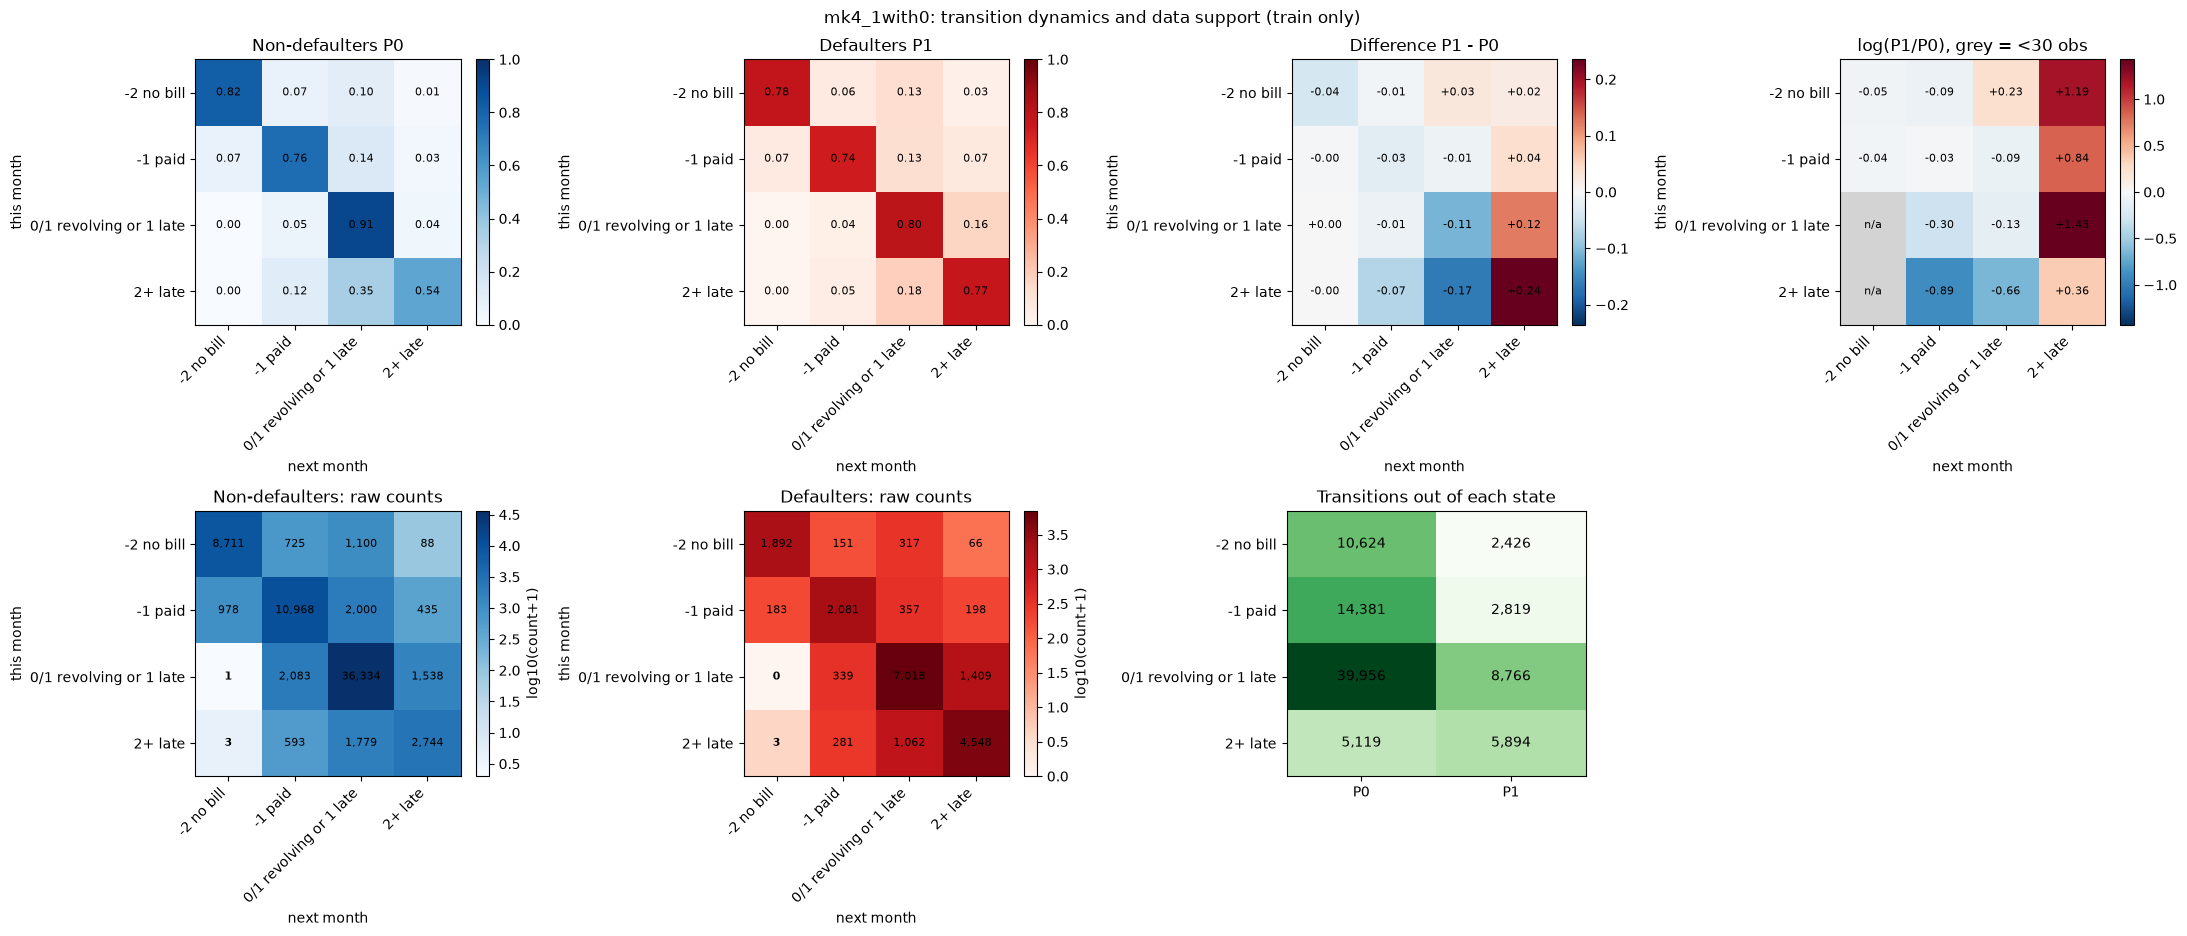

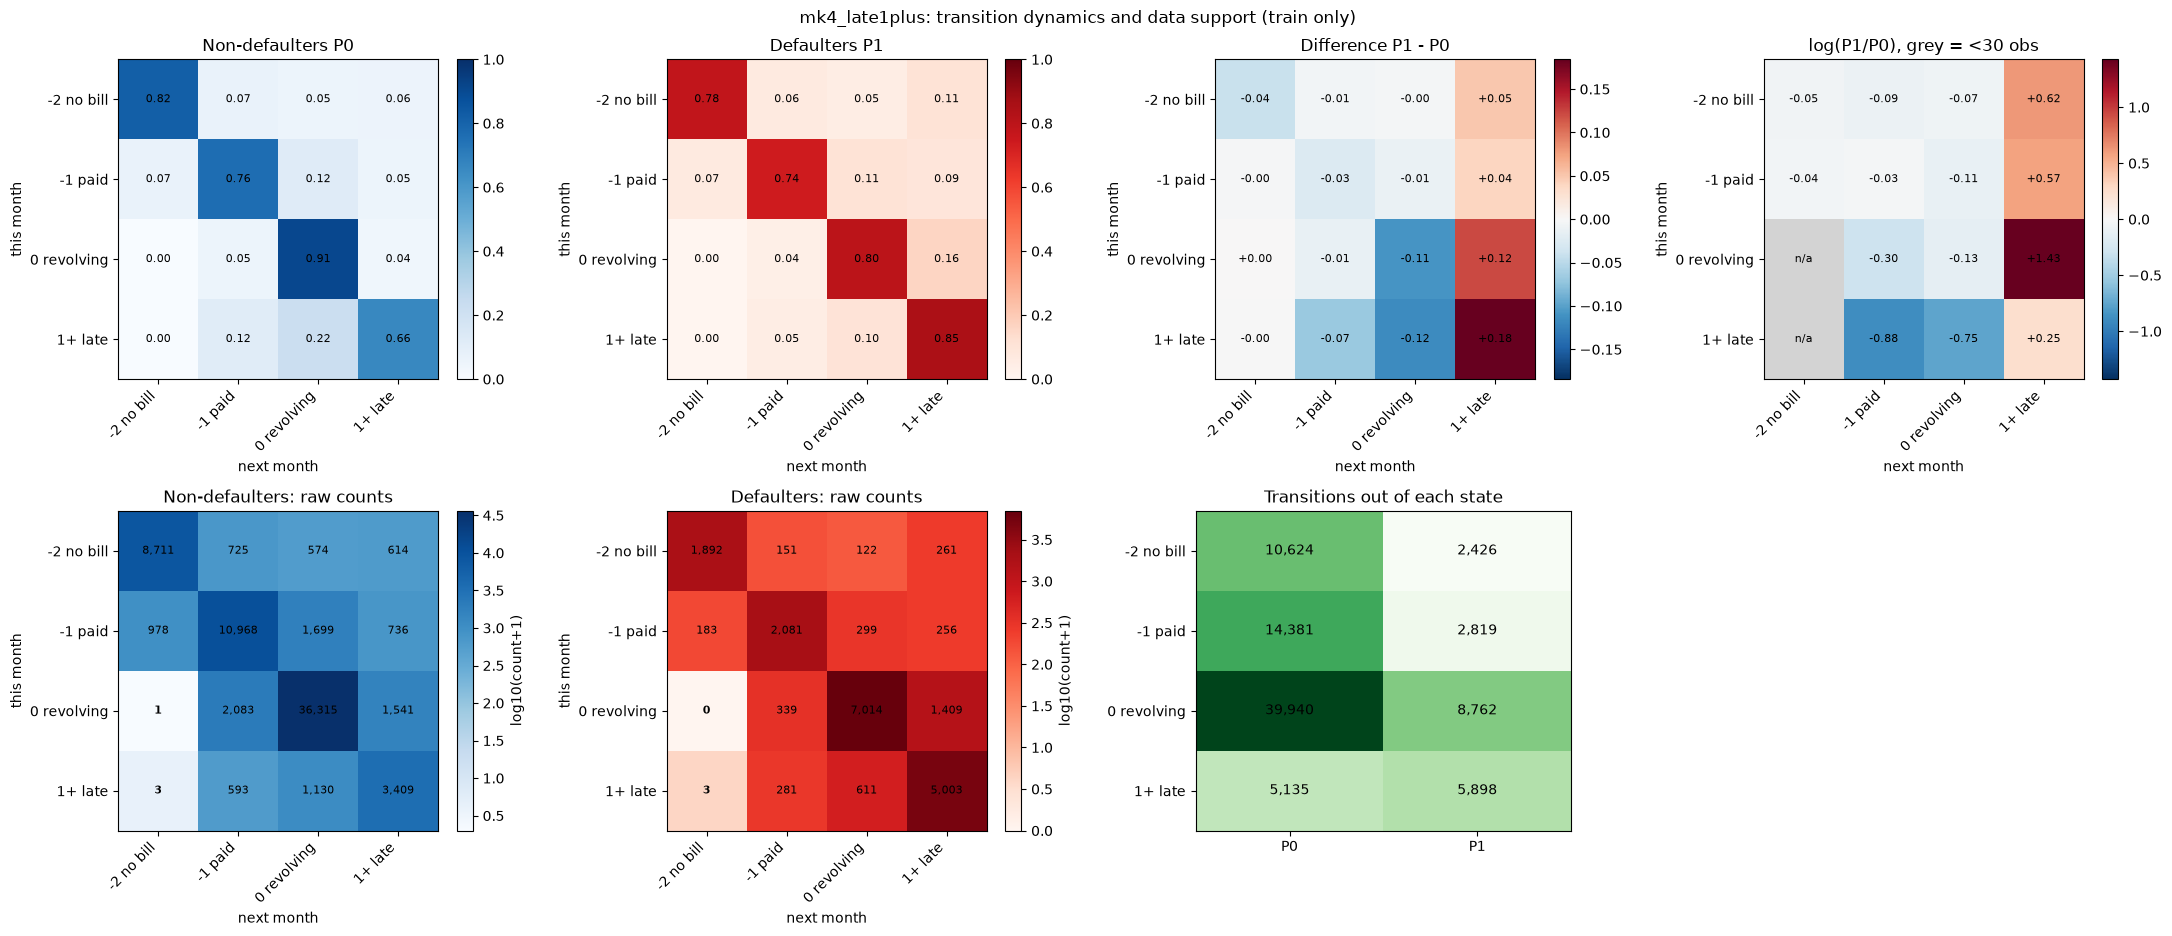

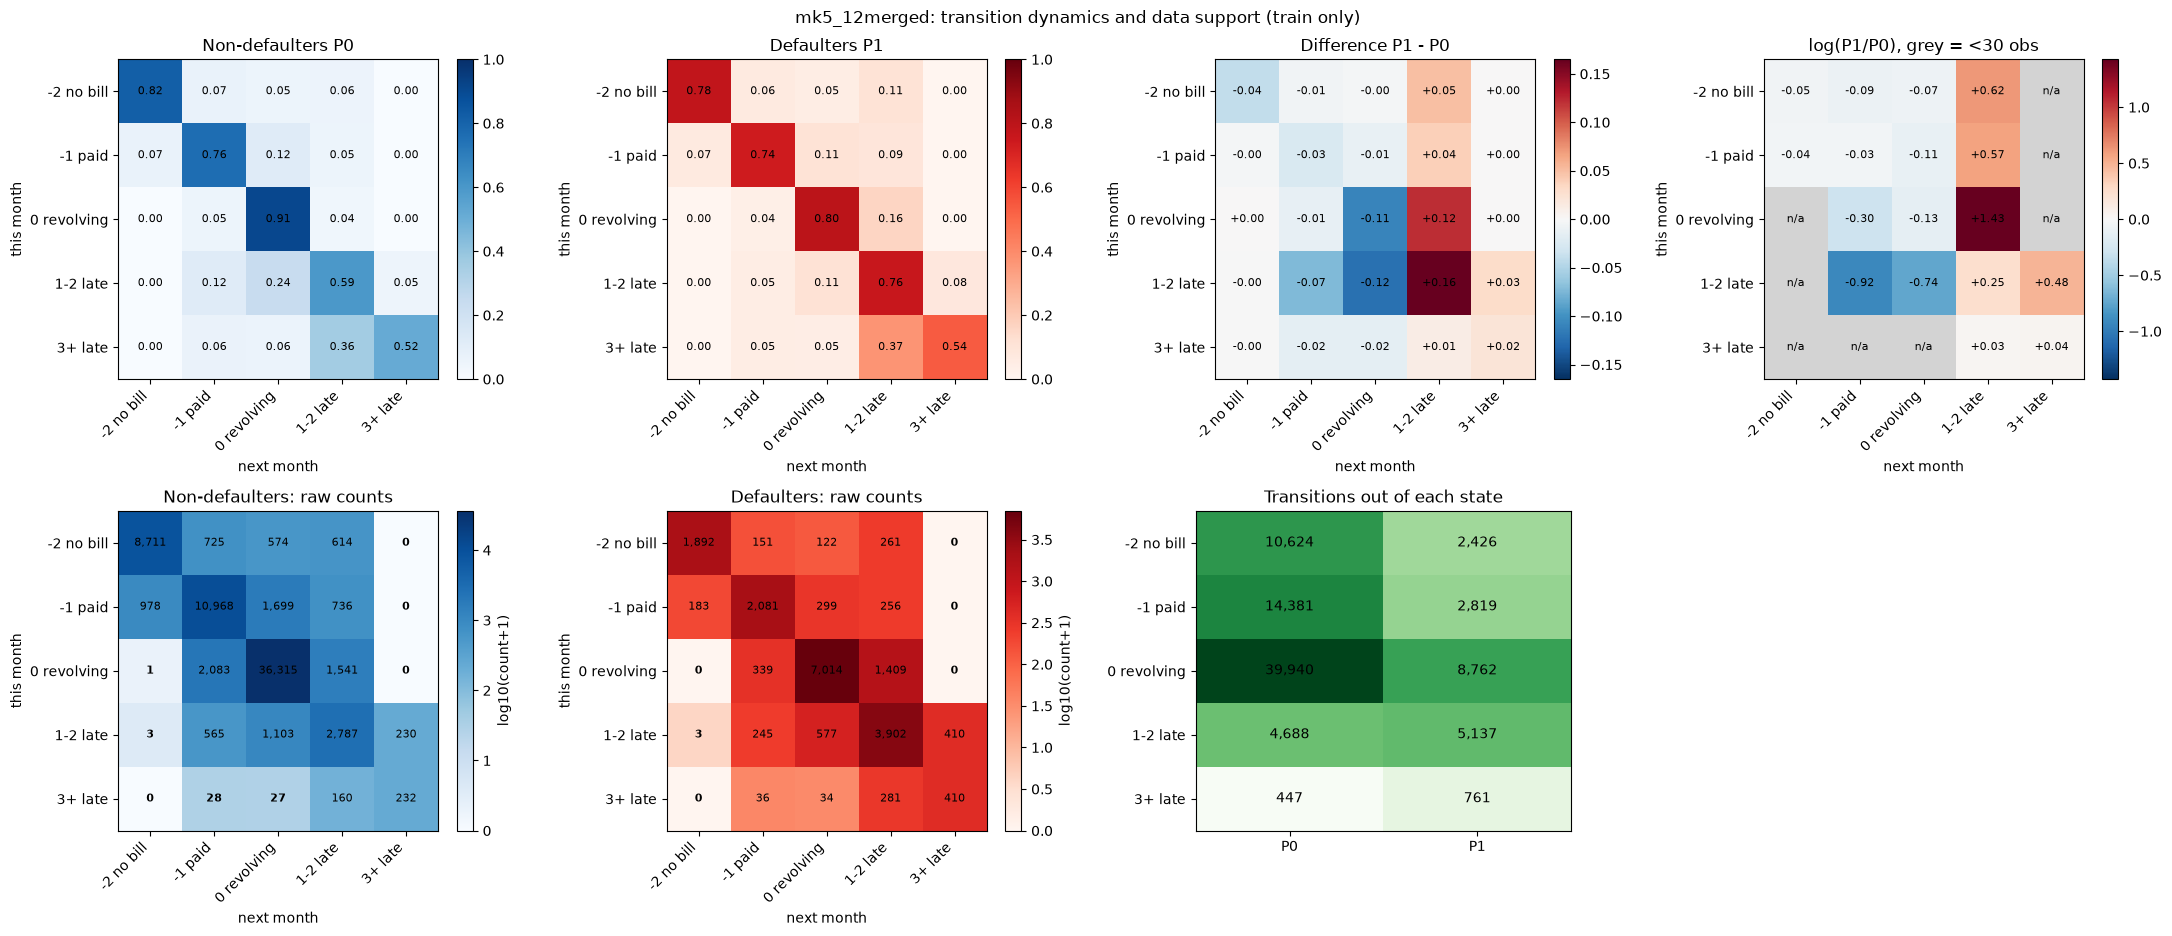

In [6]:
MIN_N = 30

def plot_class_heatmaps(key, min_n=MIN_N):
    m = markov_models[key]; K = m["K"]; lab = state_labels[key]
    P0, P1, C0, C1 = m["P0"], m["P1"], m["C0"], m["C1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(2, 4, figsize=(22, 9.5))
    top = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
           (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
           (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
           (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs[0], top):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
    for ax, C, t, cmap in [(axs[1][0], C0, "Non-defaulters: raw counts", "Blues"),
                           (axs[1][1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal")
        plt.colorbar(im, ax=ax, fraction=0.046).set_label("log10(count+1)")
    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[1][2].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[1][2].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center")
    axs[1][2].set_xticks([0, 1]); axs[1][2].set_xticklabels(["P0", "P1"])
    axs[1][2].set_title("Transitions out of each state")
    axs[1][3].axis("off")
    for ax in list(axs[0]) + list(axs[1][:3]):
        ax.set_yticks(range(K)); ax.set_yticklabels(lab)
        if ax is not axs[1][2]:
            ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
            ax.set_xlabel("next month"); ax.set_ylabel("this month")
    fig.suptitle(f"{key}: transition dynamics and data support (train only)")
    plt.tight_layout(); plt.show()

for k in markov_models:
    plot_class_heatmaps(k)

# Interpretation
Write up each model after inspecting the heatmaps and the comparison table: which transitions separate the classes, which rows rest on few observations, and whether merging states changes validation/test AUC.